# Decision tree search
Predict restaurant ratings from business attributes. **Metric: MAE in stars — lower is better.**

Same development rows, preprocessing, and five folds as notebook 02. Saved outputs are viewable on GitHub; to rerun, install `requirements-modeling.txt` and run notebook 01 first to create the local data. AI-assisted extraction and feature-removal experiments.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import KFold, GridSearchCV, cross_val_score
from sklearn.metrics import mean_absolute_error
from threadpoolctl import threadpool_limits

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "data/02_processed/restaurants_development.csv").exists()), None)
assert ROOT is not None, "Run notebook 01 first to create the processed data."
spec = json.loads((ROOT / "reports/eda/feature_spec.json").read_text())
NUM, CAT = spec["numeric_candidates"], spec["categorical_candidates"]
dev = pd.read_csv(ROOT / "data/02_processed/restaurants_development.csv",
                  dtype={c: str for c in CAT})
dev[CAT] = dev[CAT].astype(object).where(dev[CAT].notna(), np.nan)
assert dev.business_id.is_unique and dev["split"].eq("development").all()
assert dev.stars.notna().all() and dev.stars.between(1, 5).all()
X, y = dev[NUM + CAT], dev.stars.to_numpy()
SEED = 6021
folds = list(KFold(n_splits=5, shuffle=True, random_state=SEED).split(X))
BLUE, ORANGE = "#276A86", "#B56A3D"
plt.rcParams.update({"figure.dpi": 120, "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
print(f"{len(dev):,} restaurants | {len(NUM + CAT)} features | 5 folds | sklearn {sklearn.__version__}")

41,802 restaurants | 15 features | 5 folds | sklearn 1.2.1


In [2]:
def tree_pipeline(numeric, categorical):
    # Each training fold learns its own imputation and encoding.
    blocks = []
    if numeric:
        blocks += [
            ("numeric", Pipeline([("impute", SimpleImputer(strategy="median")),
                                   ("scale", StandardScaler())]), numeric),
            ("missing", MissingIndicator(features="all"), numeric),
        ]
    if categorical:
        blocks.append(("categorical", Pipeline([
            ("impute", SimpleImputer(strategy="constant", fill_value="Unknown")),
            ("encode", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                     min_frequency=50, sparse_output=False)),
        ]), categorical))
    return Pipeline([
        ("prepare", ColumnTransformer(blocks, sparse_threshold=0)),
        ("tree", DecisionTreeRegressor(min_samples_leaf=50, random_state=SEED)),
    ])


def neg_mae(model, inputs, actual):
    return -mean_absolute_error(actual, np.clip(model.predict(inputs), 1, 5))

## 1. Grid search
Original grid: **max depth = 4, 8, 12**; minimum leaf size = **50**. Select the lowest mean validation MAE.

In [3]:
search = GridSearchCV(
    tree_pipeline(NUM, CAT), {"tree__max_depth": [4, 8, 12]},
    scoring=neg_mae, cv=folds, return_train_score=True, refit=False, n_jobs=1,
)
with threadpool_limits(limits=2):
    search.fit(X, y)

cv = pd.DataFrame(search.cv_results_)
depths = cv["param_tree__max_depth"].astype(int).to_numpy()
validation = -cv["mean_test_score"].to_numpy()
training = -cv["mean_train_score"].to_numpy()
fold_mae = -cv[[f"split{k}_test_score" for k in range(5)]].to_numpy()
fold_sd = fold_mae.std(axis=1, ddof=1)
best = search.best_index_
best_depth = search.best_params_["tree__max_depth"]
full_scores = fold_mae[best]
print(f"Best depth: {best_depth} | minimum leaf size: 50 | validation MAE: {validation[best]:.4f} stars")

Best depth: 12 | minimum leaf size: 50 | validation MAE: 0.5614 stars


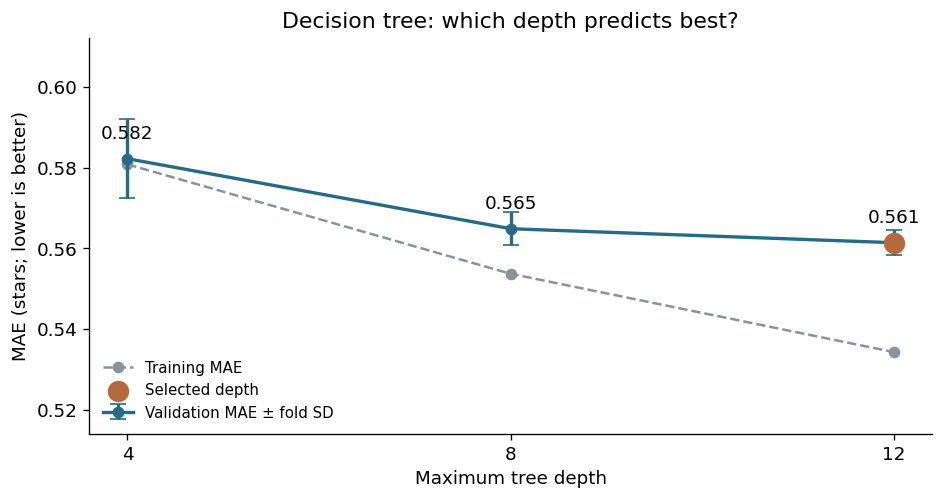

**Takeaway:** Depth **12** wins this three-setting search with validation MAE **0.561 stars**. Error bars show variation across folds, not confidence intervals.

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.3))
ax.plot(depths, training, "o--", color="#8B9299", label="Training MAE")
ax.errorbar(depths, validation, yerr=fold_sd, fmt="o-", color=BLUE,
            capsize=5, linewidth=2, label="Validation MAE ± fold SD")
ax.scatter([best_depth], [validation[best]], s=140, color=ORANGE, zorder=5,
           label="Selected depth")
for depth, score in zip(depths, validation):
    ax.annotate(f"{score:.3f}", (depth, score), xytext=(0, 12),
                textcoords="offset points", ha="center")
ax.set(xticks=depths, xlabel="Maximum tree depth", ylabel="MAE (stars; lower is better)",
       title="Decision tree: which depth predicts best?")
ax.margins(y=.35)
ax.legend(frameon=False, fontsize=9, loc="lower left")
fig.tight_layout()
plt.show()
plt.close(fig)
display(Markdown(f"**Takeaway:** Depth **{best_depth}** wins this three-setting search "
                 f"with validation MAE **{validation[best]:.3f} stars**. "
                 "Error bars show variation across folds, not confidence intervals."))

## 2. Feature ablations
New comparisons added to the original search: remove one feature group, refit, and compare on the **same folds**. Keep the selected depth and leaf size fixed; removing numeric inputs also removes their missingness indicators.

Geography = latitude, longitude, state, city/state. Numeric = geography coordinates, category count, listed days, weekly hours. Categorical = location labels, price tier, and restaurant attributes.

In [5]:
geography = {"latitude", "longitude", "state", "city_state"}
variants = {
    "Remove geography": ([c for c in NUM if c not in geography],
                         [c for c in CAT if c not in geography]),
    "Remove numeric inputs": ([], CAT),
    "Remove categorical inputs": (NUM, []),
}
scores = {"All features": full_scores}
with threadpool_limits(limits=2):
    for label, (numeric, categorical) in variants.items():
        model = tree_pipeline(numeric, categorical).set_params(**search.best_params_)
        scores[label] = -cross_val_score(model, X, y, cv=folds, scoring=neg_mae, n_jobs=1)

scores = pd.DataFrame(scores, index=range(1, 6))
scores.index.name = "fold"
means = scores.mean()
deltas = scores.drop(columns="All features").sub(scores["All features"], axis=0)
assert scores.shape == (5, 4) and np.isfinite(scores.to_numpy()).all()

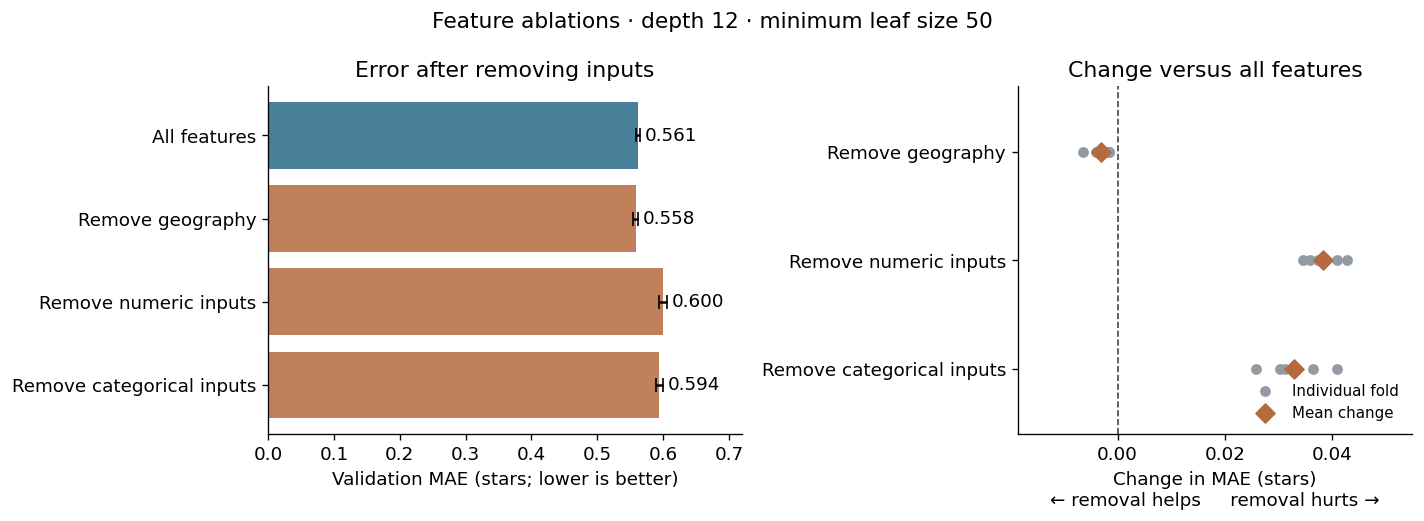

**Takeaway:** The largest mean MAE change is **+0.038 stars** for **remove numeric inputs**. These are development comparisons at fixed tree settings; they do not measure causal effects or final test performance.

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), gridspec_kw={"width_ratios": [1.2, 1]})
positions = np.arange(len(means))
axes[0].barh(positions, means, color=[BLUE, ORANGE, ORANGE, ORANGE], alpha=.85,
             xerr=scores.std(), capsize=4)
for i, value in enumerate(means):
    axes[0].text(value + scores.std().iloc[i] + .008, i, f"{value:.3f}", va="center")
axes[0].set(yticks=positions, yticklabels=means.index, xlim=(0, means.max() * 1.2),
            xlabel="Validation MAE (stars; lower is better)", title="Error after removing inputs")
axes[0].invert_yaxis()

for i, label in enumerate(deltas.columns):
    axes[1].scatter(deltas[label], np.full(5, i), color="#939BA2", s=30,
                    label="Individual fold" if i == 0 else None)
axes[1].scatter(deltas.mean(), range(3), color=ORANGE, marker="D", s=65,
                zorder=3, label="Mean change")
axes[1].axvline(0, color="#444444", linestyle="--", linewidth=1)
axes[1].set(yticks=range(3), yticklabels=deltas.columns,
            xlabel="Change in MAE (stars)\n← removal helps     removal hurts →",
            title="Change versus all features")
axes[1].invert_yaxis()
axes[1].margins(x=.25, y=.3)
axes[1].legend(frameon=False, fontsize=9, loc="lower right")
fig.suptitle(f"Feature ablations · depth {best_depth} · minimum leaf size 50", fontsize=13)
fig.tight_layout()
plt.show()
plt.close(fig)

largest = deltas.mean().idxmax()
change = deltas.mean()[largest]
display(Markdown(f"**Takeaway:** The largest mean MAE change is **{change:+.3f} stars** "
                 f"for **{largest.lower()}**. These are development comparisons at fixed tree "
                 "settings; they do not measure causal effects or final test performance."))

Only development data is used here. The test set was previously evaluated in notebook 02; these selection/ablation scores are exploratory. Source: [02_restaurant_ratings_modeling.ipynb](02_restaurant_ratings_modeling.ipynb).